<a href="https://colab.research.google.com/github/yeattinbalasy/ML_Safe_Communication/blob/main/PR4_LSTM_Safe_Communication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практическая работа №4
## Разработка и обучение нейронной сети для решения прикладной задачи

**Предметная область:** интеллектуальная система безопасного общения  
**Вариант:** 45  
**Задача:** определение токсичных и недопустимых сообщений  
**Датасет:** Jigsaw Toxic Comment Classification Challenge  
**Тип сети:** LSTM  
**Архитектура:** Embedding → LSTM → Dropout → Dense


### Цель работы

Разработать и обучить рекуррентную нейронную сеть LSTM для бинарной классификации
пользовательских сообщений, оценить её качество, визуализировать процесс обучения и
провести эксперименты с гиперпараметрами.

Исходные категории `toxic`, `severe_toxic`, `obscene`, `threat`, `insult` и
`identity_hate` объединены в целевой признак `is_toxic`:

- `0` — безопасное сообщение;
- `1` — токсичное сообщение.


### 1. Подключение библиотек и настройка воспроизводимости


In [1]:
from pathlib import Path
import html
import random
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve
)
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, TextVectorization, Embedding, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 2. Загрузка датасета

Поместите файл `jigsaw_toxic_30000.csv` рядом с ноутбуком. Если файл отсутствует и
ноутбук запущен в Google Colab, появится окно выбора файла.


In [2]:
from pathlib import Path
from urllib.request import urlretrieve

DATA_PATH = Path("jigsaw_toxic_30000.csv")

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "yeattinbalasy/ML_Safe_Communication/main/"
    "jigsaw_toxic_30000.csv"
)

if not DATA_PATH.exists():
    print("Датасет не найден. Выполняется автоматическая загрузка с GitHub...")
    urlretrieve(DATA_URL, DATA_PATH)
    print("Датасет успешно загружен.")

df = pd.read_csv(DATA_PATH)

print(f"Размер датасета: {df.shape[0]:,} строк, {df.shape[1]} столбцов")
display(df.head(3))

Датасет не найден. Выполняется автоматическая загрузка с GitHub...
Датасет успешно загружен.
Размер датасета: 30,000 строк, 9 столбцов


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,is_toxic
0,78691487e7ff2092,Formation of S constellations\nIs probably not...,0,0,0,0,0,0,0
1,67ba2331d65352ec,I think the ESPN sports announcer used that wo...,0,0,0,0,0,0,0
2,258b938fb57228ec,"wrong, its made very clear Nemanja's parents a...",0,0,0,0,0,0,0


### 3. Исследовательский анализ данных


In [3]:
LABEL_COLUMNS = [
    "toxic", "severe_toxic", "obscene",
    "threat", "insult", "identity_hate"
]
required = {"id", "comment_text", "is_toxic", *LABEL_COLUMNS}
missing_columns = required - set(df.columns)
if missing_columns:
    raise ValueError(f"Отсутствуют столбцы: {sorted(missing_columns)}")

print("Пропущенные значения:")
print(df.isna().sum().to_string())
print("\nПолные дубликаты:", int(df.duplicated().sum()))
print("Дубликаты текста:", int(df.duplicated(subset=["comment_text"]).sum()))

class_table = pd.DataFrame({
    "Количество": df["is_toxic"].value_counts().sort_index(),
    "Доля, %": (df["is_toxic"].value_counts(normalize=True).sort_index() * 100).round(2)
})
class_table.index = ["Безопасные (0)", "Токсичные (1)"]
display(class_table)


Пропущенные значения:
id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
is_toxic         0

Полные дубликаты: 0
Дубликаты текста: 0


,Количество,"Доля, %"
Безопасные (0),26950,89.83
Токсичные (1),3050,10.17


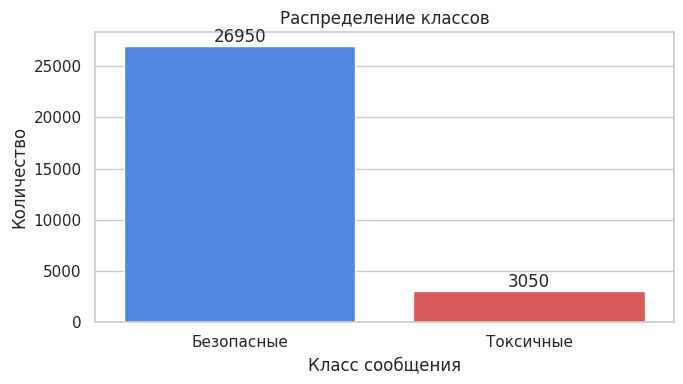

In [4]:
class_counts = df["is_toxic"].value_counts().sort_index()
plt.figure(figsize=(7, 4))
ax = sns.barplot(
    x=["Безопасные", "Токсичные"],
    y=class_counts.values,
    palette=["#3B82F6", "#EF4444"]
)
ax.set_title("Распределение классов")
ax.set_xlabel("Класс сообщения")
ax.set_ylabel("Количество")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.tight_layout()
plt.savefig("pr4_class_distribution.png", dpi=160, bbox_inches="tight")
plt.show()


### 4. Предобработка текста

Выполняются декодирование HTML, замена ссылок токеном `URL`, приведение к нижнему
регистру, удаление лишних пробелов, пустых сообщений и дубликатов.


In [5]:
def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"https?://\S+|www\.\S+", " URL ", text)
    text = re.sub(r"\s+", " ", text).strip().lower()
    return text

df = df.drop_duplicates(subset=["comment_text"]).copy()
df["comment_text"] = df["comment_text"].fillna("").map(clean_text)
df = df[df["comment_text"].str.len() > 0].reset_index(drop=True)
df["text_length"] = df["comment_text"].str.len()

print("Размер после предобработки:", df.shape)
display(df["text_length"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(2))


Размер после предобработки: (30000, 10)


,text_length
count,30000.00
mean,382.19
std,576.80
min,5.00
50%,198.00
90%,861.00
95%,1318.00
99%,3321.11
max,5000.00


### 5. Разделение данных

Используется разделение 80/10/10 со стратификацией:

- 80% — обучение;
- 10% — проверка во время настройки гиперпараметров;
- 10% — финальное тестирование.


In [6]:
X = df["comment_text"].astype(str)
y = df["is_toxic"].astype(int)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print("Обучающая выборка:", len(X_train))
print("Валидационная выборка:", len(X_val))
print("Тестовая выборка:", len(X_test))
print("Доля токсичных в train:", round(y_train.mean(), 4))
print("Доля токсичных в val:", round(y_val.mean(), 4))
print("Доля токсичных в test:", round(y_test.mean(), 4))


Обучающая выборка: 24000
Валидационная выборка: 3000
Тестовая выборка: 3000
Доля токсичных в train: 0.1017
Доля токсичных в val: 0.1017
Доля токсичных в test: 0.1017


### 6. Векторизация текста и веса классов

Слой `TextVectorization` формирует словарь только по обучающей выборке. Каждое
сообщение преобразуется в последовательность из 200 целых чисел. Веса классов
компенсируют дисбаланс между безопасными и токсичными сообщениями.


In [7]:
MAX_TOKENS = 20000
SEQUENCE_LENGTH = 200

vectorizer = TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH,
    standardize=None
)
vectorizer.adapt(X_train.values)

classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
CLASS_WEIGHT = {int(cls): float(weight) for cls, weight in zip(classes, weights)}

print("Размер словаря:", len(vectorizer.get_vocabulary()))
print("Веса классов:", CLASS_WEIGHT)
print("Пример последовательности:", vectorizer([X_train.iloc[0]]).numpy()[0][:20])


Размер словаря: 20000
Веса классов: {0: 0.5565862708719852, 1: 4.918032786885246}
Пример последовательности: [   73    14   404  1214    24    44     1 19170    38     7    95     3
 13852     7  1575    13     2   414     1     0]


### 7. Архитектура LSTM

Архитектура соответствует методическим рекомендациям:

1. `Embedding` переводит номера слов в обучаемые плотные векторы.
2. `LSTM` учитывает порядок слов и долгосрочные зависимости в тексте.
3. `Dropout` случайно отключает часть нейронов и уменьшает переобучение.
4. `Dense(1, sigmoid)` возвращает вероятность токсичного класса.


In [8]:
def build_lstm_model(embedding_dim, lstm_units, dropout_rate, learning_rate):
    model = Sequential([
        Input(shape=(), dtype=tf.string, name="message"),
        vectorizer,
        Embedding(
            input_dim=len(vectorizer.get_vocabulary()),
            output_dim=embedding_dim,
            mask_zero=True,
            name="embedding"
        ),
        LSTM(lstm_units, name="lstm"),
        Dropout(dropout_rate, name="dropout"),
        Dense(1, activation="sigmoid", name="prediction")
    ])

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="auc")
        ]
    )
    return model

preview_model = build_lstm_model(64, 64, 0.3, 1e-3)
preview_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 200)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prediction (Dense)              │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,089 (5.01 MB)

 Trainable params: 1,313,089 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

### 8. Эксперименты с гиперпараметрами

Проводятся три эксперимента:

- базовая модель;
- модель с увеличенным Dropout;
- увеличенная LSTM с более низкой скоростью обучения.

`EarlyStopping` прекращает обучение, если валидационная ошибка не улучшается, а
`ReduceLROnPlateau` уменьшает скорость обучения при выходе на плато.


In [9]:
EXPERIMENTS = [
    {
        "name": "Baseline",
        "embedding_dim": 64,
        "lstm_units": 64,
        "dropout_rate": 0.30,
        "learning_rate": 1e-3,
        "batch_size": 64,
        "epochs": 8
    },
    {
        "name": "High Dropout",
        "embedding_dim": 64,
        "lstm_units": 64,
        "dropout_rate": 0.50,
        "learning_rate": 1e-3,
        "batch_size": 64,
        "epochs": 8
    },
    {
        "name": "Larger LSTM",
        "embedding_dim": 128,
        "lstm_units": 128,
        "dropout_rate": 0.40,
        "learning_rate": 5e-4,
        "batch_size": 128,
        "epochs": 8
    }
]

pd.DataFrame(EXPERIMENTS)


,name,embedding_dim,lstm_units,dropout_rate,learning_rate,batch_size,epochs
0,Baseline,64,64,0.3,0.0010,64,8
1,High Dropout,64,64,0.5,0.0010,64,8
2,Larger LSTM,128,128,0.4,0.0005,128,8


In [10]:
histories = {}
models = {}
results = []
validation_predictions = {}
test_predictions = {}
test_scores = {}

for config in EXPERIMENTS:
    name = config["name"]
    print("\n" + "=" * 80)
    print("Эксперимент:", name)

    model = build_lstm_model(
        embedding_dim=config["embedding_dim"],
        lstm_units=config["lstm_units"],
        dropout_rate=config["dropout_rate"],
        learning_rate=config["learning_rate"]
    )

    callbacks = [
        EarlyStopping(
            monitor="val_loss", patience=2,
            restore_best_weights=True, verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss", factor=0.5,
            patience=1, min_lr=1e-5, verbose=1
        )
    ]

    started = time.perf_counter()
    history = model.fit(
        X_train.values,
        y_train.values,
        validation_data=(X_val.values, y_val.values),
        epochs=config["epochs"],
        batch_size=config["batch_size"],
        class_weight=CLASS_WEIGHT,
        callbacks=callbacks,
        verbose=1
    )
    train_time = time.perf_counter() - started

    val_score = model.predict(X_val.values, batch_size=256, verbose=0).ravel()
    val_pred = (val_score >= 0.5).astype(int)
    y_score = model.predict(X_test.values, batch_size=256, verbose=0).ravel()
    y_pred = (y_score >= 0.5).astype(int)

    result = {
        "Эксперимент": name,
        "Embedding": config["embedding_dim"],
        "LSTM": config["lstm_units"],
        "Dropout": config["dropout_rate"],
        "Learning rate": config["learning_rate"],
        "Batch": config["batch_size"],
        "Эпох выполнено": len(history.history["loss"]),
        "Validation F1": f1_score(y_val, val_pred),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score),
        "Время, с": train_time
    }

    histories[name] = history
    models[name] = model
    validation_predictions[name] = val_pred
    test_predictions[name] = y_pred
    test_scores[name] = y_score
    results.append(result)

results_df = pd.DataFrame(results).sort_values(
    "Validation F1", ascending=False
).reset_index(drop=True)
display(results_df.round(4))



Эксперимент: Baseline
Epoch 1/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.8201 - auc: 0.8682 - loss: 0.4563 - precision: 0.3314 - recall: 0.7561 - val_accuracy: 0.8707 - val_auc: 0.9218 - val_loss: 0.3796 - val_precision: 0.4288 - val_recall: 0.8197 - learning_rate: 0.0010
Epoch 2/8
372/375 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9211 - auc: 0.9624 - loss: 0.2426 - precision: 0.5619 - recall: 0.8949
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.9183 - auc: 0.9651 - loss: 0.2363 - precision: 0.5607 - recall: 0.9045 - val_accuracy: 0.8467 - val_auc: 0.9303 - val_loss: 0.4051 - val_precision: 0.3862 - val_recall: 0.8623 - learning_rate: 0.0010
Epoch 3/8
372/375 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9477 - auc: 0.9870 - loss: 0.1421 - precision: 0.6666 - recall: 0.9505
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
375/375 ━━━━━━━━━━━━━━━━━━━━

,Эксперимент,Embedding,LSTM,Dropout,Learning rate,Batch,Эпох выполнено,Validation F1,Accuracy,Precision,Recall,F1-score,ROC-AUC,"Время, с"
0,High Dropout,64,64,0.5,0.0010,64,5,0.6067,0.9023,0.5136,0.7410,0.6067,0.9228,29.8726
1,Larger LSTM,128,128,0.4,0.0005,128,5,0.5852,0.8787,0.4451,0.7836,0.5677,0.9162,20.7768
2,Baseline,64,64,0.3,0.0010,64,3,0.5631,0.8560,0.3977,0.8098,0.5335,0.9108,25.9706


### 9. Визуализация процесса обучения


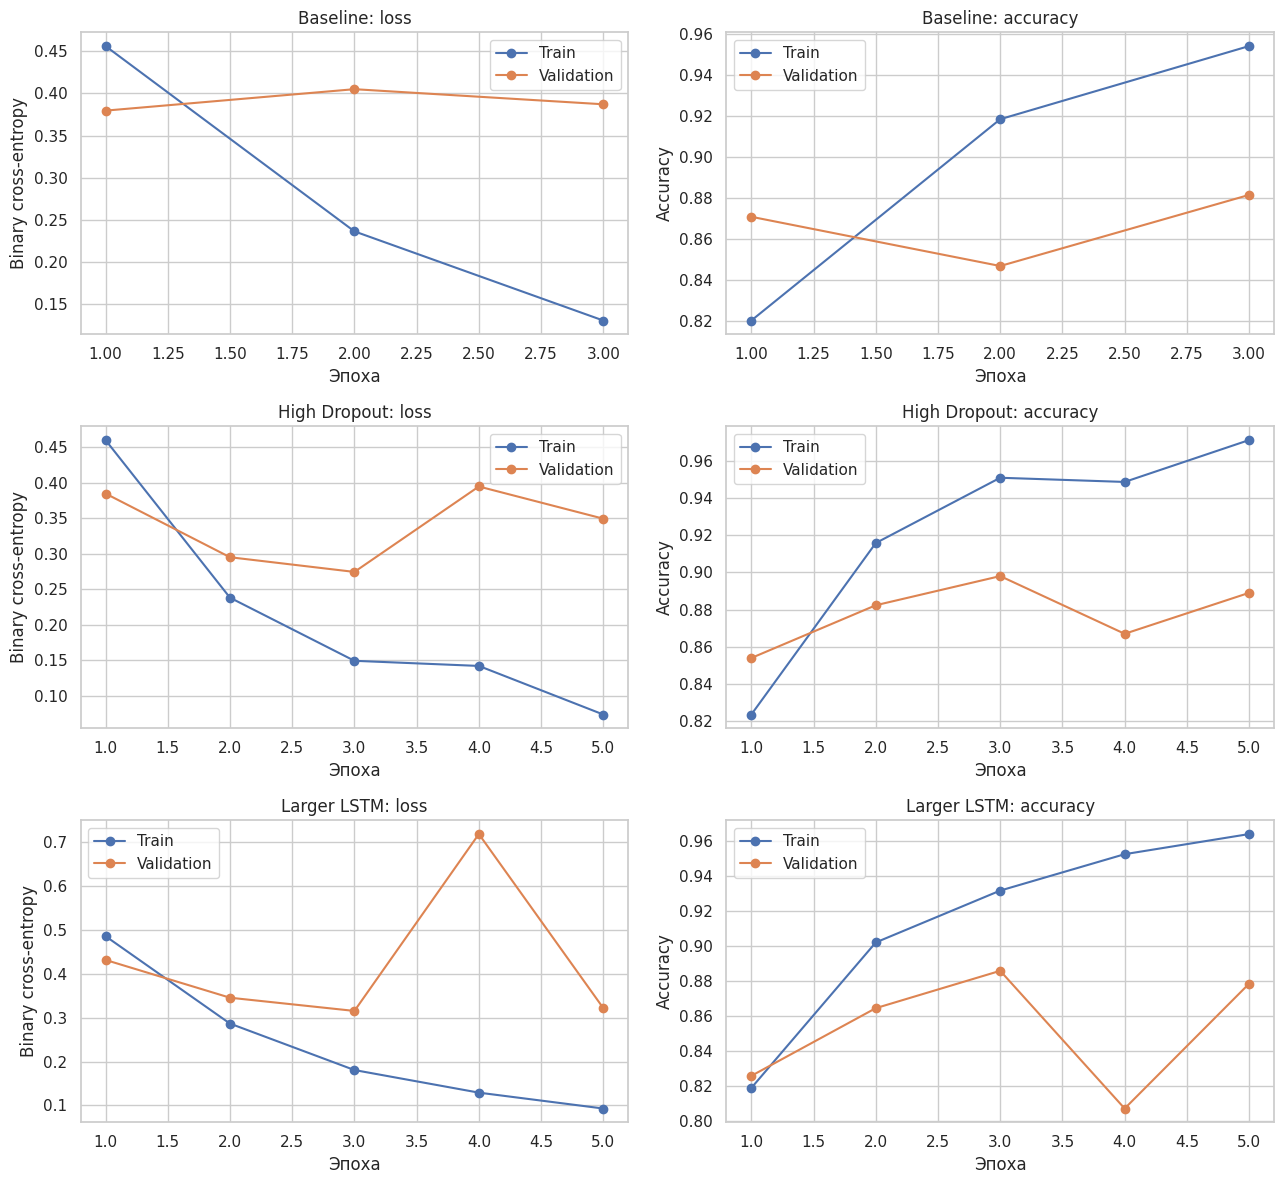

In [11]:
fig, axes = plt.subplots(len(EXPERIMENTS), 2, figsize=(13, 4 * len(EXPERIMENTS)))

for row, config in enumerate(EXPERIMENTS):
    name = config["name"]
    history = histories[name].history
    epochs_range = range(1, len(history["loss"]) + 1)

    axes[row, 0].plot(epochs_range, history["loss"], marker="o", label="Train")
    axes[row, 0].plot(epochs_range, history["val_loss"], marker="o", label="Validation")
    axes[row, 0].set_title(f"{name}: loss")
    axes[row, 0].set_xlabel("Эпоха")
    axes[row, 0].set_ylabel("Binary cross-entropy")
    axes[row, 0].legend()

    axes[row, 1].plot(epochs_range, history["accuracy"], marker="o", label="Train")
    axes[row, 1].plot(epochs_range, history["val_accuracy"], marker="o", label="Validation")
    axes[row, 1].set_title(f"{name}: accuracy")
    axes[row, 1].set_xlabel("Эпоха")
    axes[row, 1].set_ylabel("Accuracy")
    axes[row, 1].legend()

plt.tight_layout()
plt.savefig("pr4_training_history.png", dpi=160, bbox_inches="tight")
plt.show()


### 10. Сравнение экспериментов

Лучшая конфигурация выбирается по F1-score на **валидационной** выборке. Тестовая
выборка используется для финальной независимой оценки.


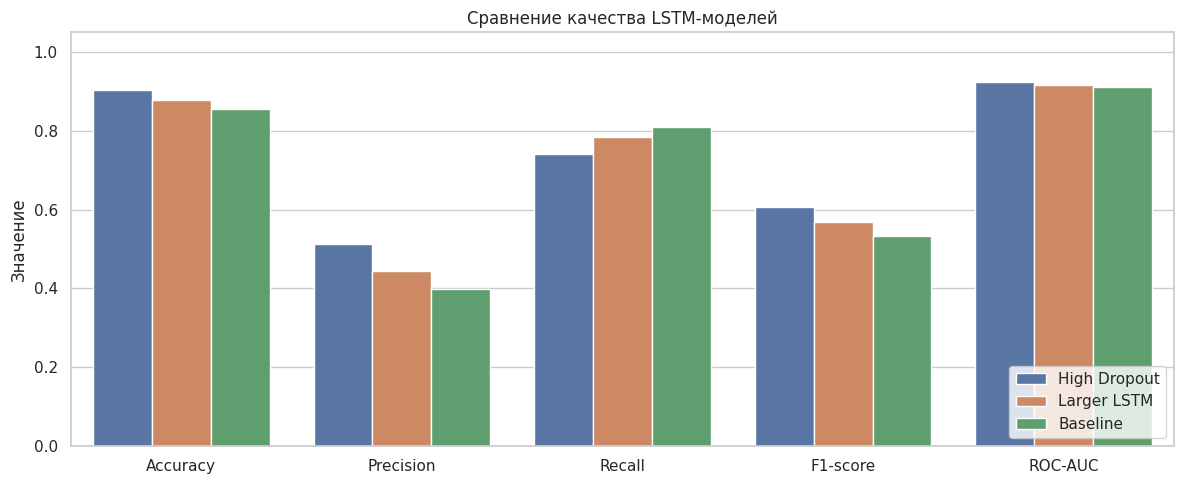

In [12]:
metric_columns = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
plot_df = results_df.melt(
    id_vars="Эксперимент",
    value_vars=metric_columns,
    var_name="Метрика",
    value_name="Значение"
)

plt.figure(figsize=(12, 5))
ax = sns.barplot(data=plot_df, x="Метрика", y="Значение", hue="Эксперимент")
ax.set_ylim(0, 1.05)
ax.set_title("Сравнение качества LSTM-моделей")
ax.set_xlabel("")
ax.set_ylabel("Значение")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("pr4_experiment_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

results_df.to_csv("pr4_lstm_experiment_results.csv", index=False)


In [13]:
best_name = results_df.loc[0, "Эксперимент"]
best_model = models[best_name]
best_pred = test_predictions[best_name]
best_score = test_scores[best_name]

print("Лучшая конфигурация по Validation F1:", best_name)
print("\nОтчёт на тестовой выборке:")
print(classification_report(
    y_test, best_pred,
    target_names=["Безопасное", "Токсичное"],
    digits=4, zero_division=0
))


Лучшая конфигурация по Validation F1: High Dropout

Отчёт на тестовой выборке:
              precision    recall  f1-score   support

  Безопасное     0.9691    0.9206    0.9442      2695
   Токсичное     0.5136    0.7410    0.6067       305

    accuracy                         0.9023      3000
   macro avg     0.7414    0.8308    0.7755      3000
weighted avg     0.9228    0.9023    0.9099      3000



### 11. Матрица ошибок и ROC-кривая лучшей модели


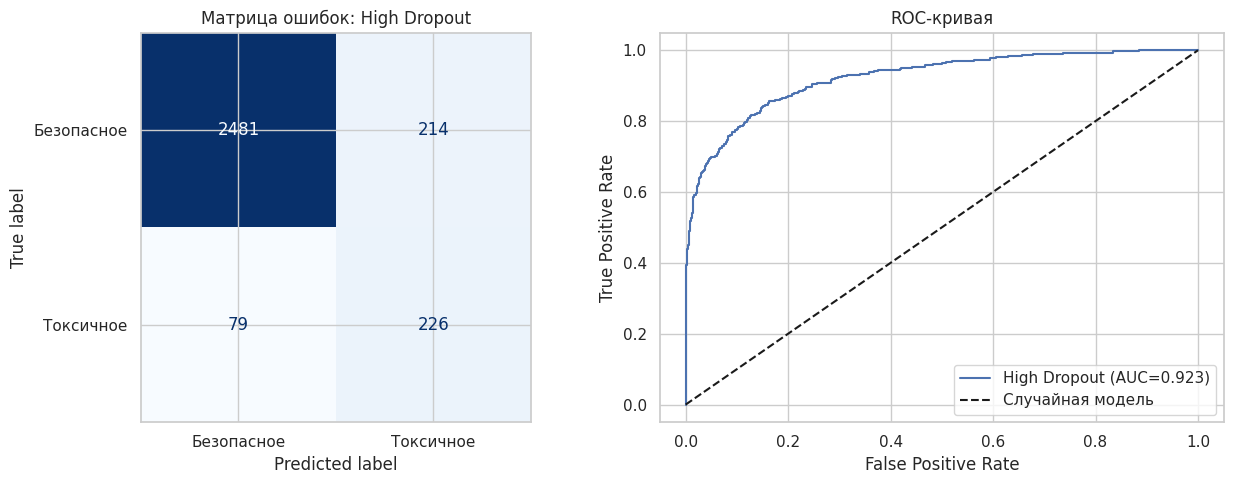

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, best_pred)
ConfusionMatrixDisplay(
    cm, display_labels=["Безопасное", "Токсичное"]
).plot(ax=axes[0], colorbar=False, cmap="Blues", values_format="d")
axes[0].set_title(f"Матрица ошибок: {best_name}")

fpr, tpr, _ = roc_curve(y_test, best_score)
auc = roc_auc_score(y_test, best_score)
axes[1].plot(fpr, tpr, label=f"{best_name} (AUC={auc:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Случайная модель")
axes[1].set_title("ROC-кривая")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()

plt.tight_layout()
plt.savefig("pr4_best_model_evaluation.png", dpi=160, bbox_inches="tight")
plt.show()


### 12. Примеры верных и ошибочных предсказаний


In [15]:
prediction_table = pd.DataFrame({
    "message": X_test.values,
    "true_class": y_test.values,
    "predicted_class": best_pred,
    "toxicity_probability": best_score
})
prediction_table["correct"] = (
    prediction_table["true_class"] == prediction_table["predicted_class"]
)

print("Примеры верных предсказаний:")
display(prediction_table[prediction_table["correct"]].sample(
    5, random_state=RANDOM_STATE
))

print("Примеры ошибочных предсказаний:")
errors = prediction_table[~prediction_table["correct"]]
display(errors.head(10) if len(errors) >= 10 else errors)


Примеры верных предсказаний:


,message,true_class,predicted_class,toxicity_probability,correct
1148,""" i'm not married to that cite. i'm fine with ...",0,0,0.010028,True
488,dawood ibrahim the debate over whether to have...,0,0,0.015303,True
1920,wikipedia is not a place for.... have little a...,0,0,0.002379,True
329,"not noteworthy, and i also reverted the prescr...",0,0,0.010601,True
2444,i understand the value of this project:::: hi ...,0,0,0.033472,True


Примеры ошибочных предсказаний:


,message,true_class,predicted_class,toxicity_probability,correct
13,riiiight. and you too.,0,1,0.736509,False
44,url is really laughable by the way. it's nothi...,0,1,0.959440,False
55,teh intarweb would nevar lie to me!!!,0,1,0.776119,False
66,"you changed it back idiot, i did leave my reas...",1,0,0.437505,False
71,"""""""because it backs my claims""""""",0,1,0.606885,False
72,"""""""some white people considered black people t...",0,1,0.951796,False
73,contradicting my neo-nazi anti-serb agenda.,1,0,0.226150,False
89,"awwwwwww, did i hit a little too close to home...",1,0,0.282782,False
95,""" ^^^re-read my user-page, for this is the typ...",0,1,0.918373,False
97,listen i don't care who you are! i run things ...,0,1,0.954364,False


### 13. Проверка на новых сообщениях

Jigsaw является англоязычным датасетом, поэтому корректнее проверять модель на
английских сообщениях. Для русского языка требуется русскоязычный обучающий корпус
или многоязычная нейросеть.


In [16]:
def predict_messages(messages, threshold=0.5):
    cleaned = [clean_text(message) for message in messages]
    input_tensor = tf.constant(cleaned, dtype=tf.string)
    probabilities = best_model.predict(input_tensor, verbose=0).ravel()

    return pd.DataFrame({
        "message": messages,
        "toxicity_probability": probabilities.round(4),
        "prediction": np.where(
            probabilities >= threshold,
            "Токсичное",
            "Безопасное"
        )
    })


examples = [
    "Thank you for your help with this article.",
    "You are stupid and disgusting.",
    "I will kill you.",
    "Please review my edits when you have time."
]

display(predict_messages(examples))

,message,toxicity_probability,prediction
0,Thank you for your help with this article.,0.0903,Безопасное
1,You are stupid and disgusting.,0.9982,Токсичное
2,I will kill you.,0.9828,Токсичное
3,Please review my edits when you have time.,0.0507,Безопасное


### 14. Сохранение лучшей модели


In [17]:
MODEL_PATH = "pr4_best_lstm_toxicity.keras"
best_model.save(MODEL_PATH)
print("Модель сохранена:", MODEL_PATH)
print("Результаты экспериментов сохранены: pr4_lstm_experiment_results.csv")


Модель сохранена: pr4_best_lstm_toxicity.keras
Результаты экспериментов сохранены: pr4_lstm_experiment_results.csv


### Вывод

В работе подготовлены текстовые данные Jigsaw и разработана LSTM-сеть с архитектурой
`Embedding → LSTM → Dropout → Dense`. Проведены три эксперимента с изменением
размерности Embedding, количества LSTM-нейронов, Dropout, learning rate и batch size.
Конфигурации сравнены по Accuracy, Precision, Recall, F1-score и ROC-AUC.

Главной метрикой является F1-score токсичного класса, поскольку выборка
несбалансирована. Лучшая конфигурация выбирается по валидационной выборке, после чего
её качество оценивается на независимой тестовой выборке.

Ограничение: модель обучена на англоязычных комментариях. Для русскоязычной системы
безопасного общения потребуется русскоязычный размеченный датасет или многоязычная
архитектура.
